# Public checkpoint: reverse-process trace

Run the single code cell below in the project's **.venv (Python 3.12.11)** kernel.
This notebook is independent of the reproduction notebook's live variables.
The Windows project root is specified at the top of the cell.

Protocol: the verified public `model_1.pt`, CPU, T control 5, p controls -1/+1,
100 original reverse steps, eta=gamma=1, batch size 16, sampling seed 2026103101
reset per control, original backbone `eval_mode="train"` and self-conditioning.
One instrumented batch and one uninstrumented replay are generated per control
(64 configurations total). No training or source edits occur. Files go to a new
timestamped output directory; previous results are only read.

The wrapper calls each original reverse method once and records detached
statistics without additional model calls or random draws. Exact equality with
the uninstrumented replay and equality of final RNG states are required.
Comparison with the previously saved public samples is reported separately.

**Interpretation:** x_t is noisy and need not be near -1/+1. The forward reference
uses empirical input-channel moments and the code's independent Gaussian prior:
mean = sqrt(A) * input_mean + sqrt(1-A) * p;
variance = A * input_variance + (1-A) * T.
These are population references, not a paired reverse-path target or a confidence
band. Predicted x0 is a continuous estimate; large early values or the reported
noise-error amplification factor alone do not establish a bug. All statistics
are site-pooled; standard deviations are not SEMs. Physical temperature and
chemical-potential mapping remain unresolved.

Prepared with source inspection, syntax checks, and a synthetic wrapper test.
The real PyTorch/checkpoint run must be performed in your local environment.


Tracing p=-1: one batch of 16...


C:\Users\user\Documents\GitHub\exptm_author_code_reproduction_v1\author_source\GC_Lattice_gas\expTM_data_genenration\tm\core\backbone.py:126: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimen

Replaying p=-1 without instrumentation...
{
  "pressure_control": -1,
  "trace_equals_plain": true,
  "torch_rng_equals_plain": true,
  "max_abs_difference_plain": 0.0,
  "input_sha256": "05802d6a1ea829c19fae8a913501695a981f86a9fe6b3cf47712bbe52e88f4cd",
  "input_mean": -0.903791,
  "input_std": 0.42797409771971007,
  "final_density_16": 0.30296875,
  "previous_file_found": true,
  "previous_sha256": "cd23c84eff609cc4dcd8990d3d7d012772f0344fdccfbb90b2099e371dc7ab83",
  "equals_previous_first16": true,
  "max_abs_difference_previous": 0.0
}
Selected reverse steps (site-pooled statistics):
 t -> next | xt mean/std | forward mean/std | x0 mean/std | next mean/std
99 -> 98 | -0.9427/2.2264 | -1.0040/2.2360 | -53.6718/76.2717 | -8.5920/11.0504
98 -> 97 | -8.5920/11.0504 | -1.1175/2.2145 | -17.6880/48.0624 | -8.4352/12.5338
97 -> 96 | -8.4352/12.5338 | -1.1599/2.1930 | -12.8849/41.0054 | -8.4183/13.4843
90 -> 89 | -8.7756/16.4301 | -1.2847/2.0425 | -7.6976/29.0777 | -8.8539/16.7421
75 -> 74 

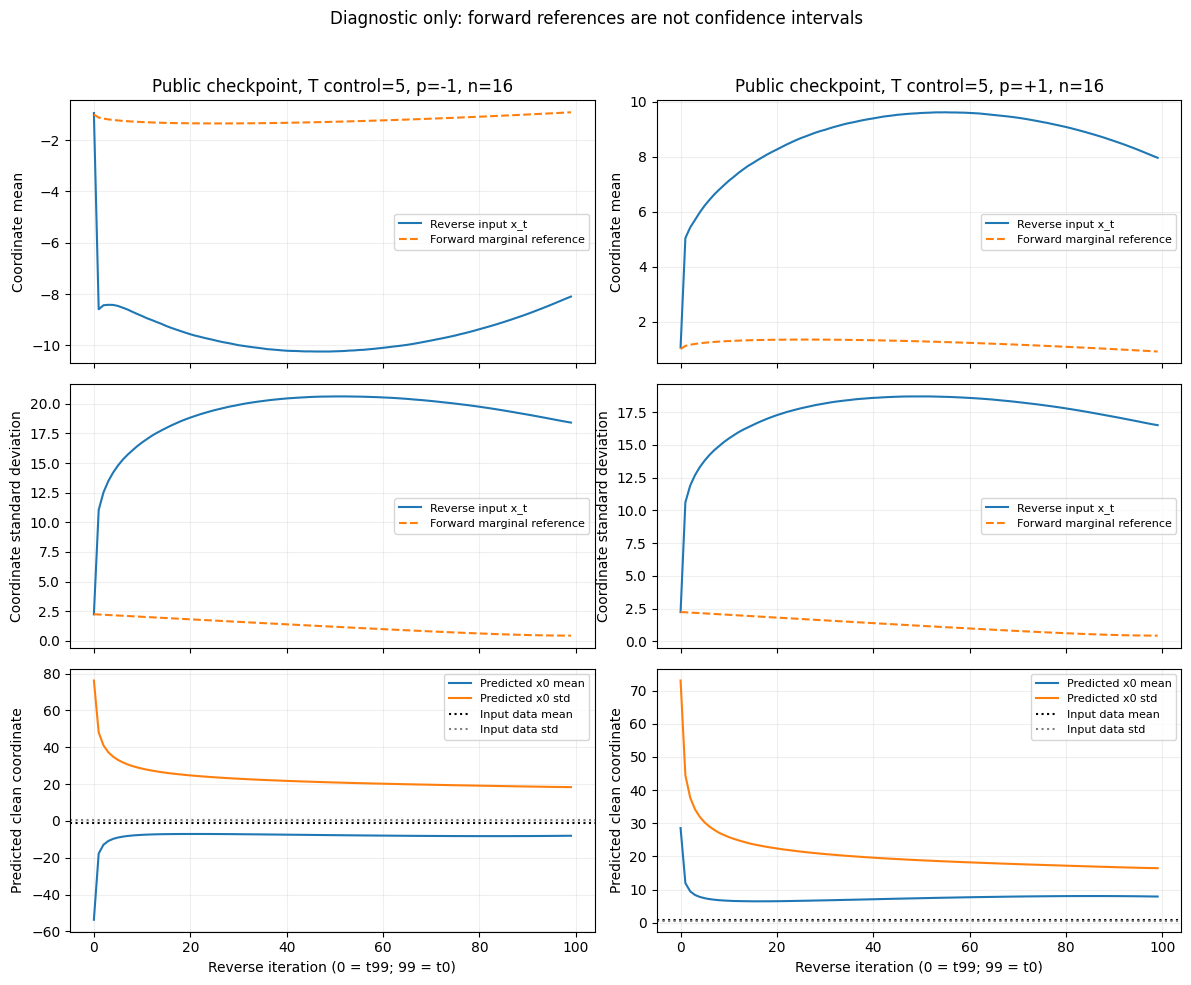


Saved to: C:\Users\user\Documents\GitHub\exptm_author_code_reproduction_v1\outputs\public_reverse_trace_20261101_013641_964176
Instrumentation equality passed. Inspect checks.json for historical replay equality.


In [1]:
from pathlib import Path
from datetime import datetime
import sys
import importlib
import hashlib
import json
import csv
import random
import platform
import numpy as np
import torch
import matplotlib.pyplot as plt

ROOT = Path(r"C:\Users\user\Documents\GitHub\exptm_author_code_reproduction_v1")
SOURCE = ROOT / "author_source" / "GC_Lattice_gas" / "expTM_data_genenration"
DATA = SOURCE.parent / "data"
CHECKPOINT = SOURCE / "thermomaps-root" / "models" / "model_1.pt"
PREVIOUS = (ROOT / "outputs" / "matched_size_2000_20261101_004025_753930"
            / "training_seed_check_20261101_005301_969905"
            / "public_checkpoint_20261101_010921_481162")
SEED = 2026103101

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

assert Path(sys.executable).resolve() == (ROOT / ".venv" / "Scripts" / "python.exe").resolve(), (
    "Select the project's .venv kernel first."
)
assert str(torch.__version__) == "2.5.1+cpu", "Use the recorded PyTorch 2.5.1+cpu environment."
assert not torch.cuda.is_available(), "This comparison uses the recorded CPU protocol."
assert torch.get_default_dtype() == torch.float32
assert sha256(CHECKPOINT) == "72125a26b5d136b8eeda782ff01fbecb99963b3ad58b8fce3f4494185f5419fc"

expected = {
    "tm.core.loader": "3ca9e881b03ddbaea1bc1f0c61cdb61e4fa5a92bb347da0f944d84960b3b2e7a",
    "tm.core.prior": "674a7427efc278ae007cafda823dcb2ebab1fe2070455d33f5968bc54b680abb",
    "tm.core.diffusion_model": "849ecf96d9b2e476bffa65e31a56028db4ab82f2db45a89cfc4aa1c1135f6dce",
    "tm.core.diffusion_process": "fb4b3c55444d736cb4db3917d663b5a5bd16c27a9a3eaba408abe1a656ae434c",
    "tm.core.backbone": "e414f5a53c456c1ffb68d910cced0cd49627c2853fe7ff19d26ebd1e2eb040d2",
    "tm.core.utils": "d5e3f31598342c2aec6b673c786c996082602bd7ca8b645d8e47ac00163b6463",
    "tm.architectures.unet_2d_mid_attn": "87f662a0474f4beb53d125afc7222b11bb30c9f2840f3e273215f76b3bf8c63c",
}
for name, digest in expected.items():
    path = SOURCE.joinpath(*name.split('.')).with_suffix('.py')
    assert sha256(path) == digest, f"Source changed: {path}. Review before running."
sys.path.insert(0, str(SOURCE)) if str(SOURCE) not in sys.path else None
modules = {name: importlib.import_module(name) for name in expected}
for name, module in modules.items():
    wanted = SOURCE.joinpath(*name.split('.')).with_suffix('.py').resolve()
    assert Path(module.__file__).resolve() == wanted, (
        f"Wrong loaded module: {name}. Restart the kernel and run this notebook only."
    )

VPDiffusion = modules['tm.core.diffusion_process'].VPDiffusion
Sampler = modules['tm.core.diffusion_model'].SteeredDiffusionSampler
Prior = modules['tm.core.prior'].GlobalEquilibriumHarmonicPrior
Backbone = modules['tm.core.backbone'].ConvBackbone
Unet = modules['tm.architectures.unet_2d_mid_attn'].Unet2D

def coordinate_stats(value):
    a = value.detach().cpu().numpy()[:, 0].astype(np.float64)
    assert np.isfinite(a).all(), "Non-finite coordinate encountered."
    q = np.quantile(a, [0.01, 0.5, 0.99])
    return dict(mean=float(a.mean()), std=float(a.std()),
                q01=float(q[0]), q50=float(q[1]), q99=float(q[2]),
                rms=float(np.sqrt(np.mean(a*a))),
                outside_unit=float(np.mean(np.abs(a) > 1)),
                positive_fraction=float(np.mean(a >= 0)))

class TracedVP(VPDiffusion):
    def __init__(self):
        super().__init__(num_diffusion_timesteps=100)
        self.rows = []

    def reverse_kernel(self, x_t, t, backbone, pred_type):
        # Exactly one original call: logging never calls the model again.
        x0, noise = super().reverse_kernel(x_t, t, backbone, pred_type)
        row = self.rows[-1]
        for prefix, value in [('xt', x_t), ('x0', x0), ('noise', noise)]:
            row.update({f'{prefix}_{k}': v for k, v in coordinate_stats(value).items()})
        row['xt_temperature_channel_mean'] = float(x_t[:, 1].mean())
        row['xt_pressure_channel_mean'] = float(x_t[:, 2].mean())
        return x0, noise

    def reverse_step(self, x_t, t, t_next, backbone, pred_type, eta, prior, **kwargs):
        step, next_step = int(t[0]), int(t_next[0])
        a = float(self.alphas[step])
        row = dict(reverse_index=len(self.rows), t=step, t_next=next_step,
                   alpha=a, alpha_next=float(self.alphas[next_step]),
                   noise_error_gain=float(np.sqrt((1-a)/a)))
        self.rows.append(row)
        result = super().reverse_step(x_t, t, t_next, backbone, pred_type, eta, prior, **kwargs)
        row.update({f'next_{k}': v for k, v in coordinate_stats(result).items()})
        return result

def make_backbone():
    model = Unet(dim=32, dim_mults=(1, 2, 4), resnet_block_groups=8, channels=3)
    bb = Backbone(model=model, data_shape=20, target_shape=32, num_dims=4,
                  lr=1e-3, eval_mode='train', self_condition=True)
    bb.load_model(str(CHECKPOINT.parent), 1, device='cpu')
    return bb

def seed_sampling():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

def run_trace():
    out = ROOT / 'outputs' / ('public_reverse_trace_' + datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
    out.mkdir(parents=True, exist_ok=False)
    config = dict(checkpoint=str(CHECKPOINT), checkpoint_sha256=sha256(CHECKPOINT),
                  source_sha256=expected, python=platform.python_version(), torch=str(torch.__version__),
                  numpy=np.__version__, device='cpu', threads=2, sampling_seed=SEED,
                  temperature_control=5, pressure_controls=[-1, 1], samples_per_control=16,
                  eta=1, gamma=1, backbone_eval_mode='train', self_condition=True,
                  loader=None, loader_note='Unused by the verified sample_loop/sample_batch path.',
                  previous_sample_directory=str(PREVIOUS), status='started')
    (out / 'config.json').write_text(json.dumps(config, indent=2), encoding='utf-8')
    prior = Prior(shape=(2000, 3, 20, 20),
                  channels_info={'coordinate':[0], 'fluctuation':[1], 'mean':[2]})
    # The prior keeps only (3,20,20); it has no fitted data statistics.
    summaries, traces = [], {}
    for p, filename in [(-1, 'LowMuT7.npy'), (1, 'HighMuT7.npy')]:
        data_path = DATA / filename
        data = np.load(data_path, mmap_mode='r', allow_pickle=False)[:, 0]
        assert data.shape[1:] == (20, 20)
        assert np.all((data == -1) | (data == 1))
        input_mean, input_var = float(data.mean()), float(data.var())
        dp = TracedVP()
        bb = make_backbone()
        sampler = Sampler(dp, bb, None, prior, pred_type='noise')
        seed_sampling()
        print(f'Tracing p={p:+d}: one batch of 16...', flush=True)
        values = sampler.sample_loop(num_samples=16, batch_size=16,
                                     temperature=5, pressure=p, eta=1, gamma=1).detach().cpu().numpy().copy()
        trace_rng = torch.get_rng_state().clone()
        assert values.shape == (16, 3, 20, 20) and np.isfinite(values).all()
        assert np.all(values[:, 1] == 5) and np.all(values[:, 2] == p)
        assert len(dp.rows) == 100
        assert [(r['t'], r['t_next']) for r in dp.rows] == [(i, max(i-1, 0)) for i in range(99, -1, -1)]
        for row in dp.rows:
            a = row['alpha']
            row.update(pressure_control=p,
                       forward_mean=np.sqrt(a)*input_mean + np.sqrt(1-a)*p,
                       forward_std=np.sqrt(a*input_var + (1-a)*5))
        traces[p] = dp.rows
        np.save(out / f'p_{p:+d}_samples.npy', values)
        (out / f'p_{p:+d}_trace.json').write_text(json.dumps(dp.rows, indent=2), encoding='utf-8')
        with (out / f'p_{p:+d}_trace.csv').open('w', newline='', encoding='utf-8') as f:
            writer = csv.DictWriter(f, fieldnames=list(dp.rows[0]))
            writer.writeheader()
            writer.writerows(dp.rows)

        print(f'Replaying p={p:+d} without instrumentation...', flush=True)
        plain_bb = make_backbone()
        plain = Sampler(VPDiffusion(num_diffusion_timesteps=100), plain_bb,
                        None, prior, pred_type='noise')
        seed_sampling()
        replay = plain.sample_loop(num_samples=16, batch_size=16,
                                   temperature=5, pressure=p, eta=1, gamma=1).detach().cpu().numpy()
        same_rng = bool(torch.equal(trace_rng, torch.get_rng_state()))
        same_values = bool(np.array_equal(values, replay))
        summary = dict(pressure_control=p, trace_equals_plain=same_values,
                       torch_rng_equals_plain=same_rng,
                       max_abs_difference_plain=float(np.max(np.abs(values-replay))),
                       input_sha256=sha256(data_path), input_mean=input_mean,
                       input_std=float(np.sqrt(input_var)),
                       final_density_16=float((values[:, 0] >= 0).mean()))
        saved = PREVIOUS / f'p_{p:+d}_samples.npy'
        summary['previous_file_found'] = saved.is_file()
        if saved.is_file():
            previous = np.load(saved, allow_pickle=False)[:16]
            assert previous.shape == values.shape
            summary.update(previous_sha256=sha256(saved),
                           equals_previous_first16=bool(np.array_equal(values, previous)),
                           max_abs_difference_previous=float(np.max(np.abs(values-previous))))
        summaries.append(summary)
        (out / 'checks.json').write_text(json.dumps(summaries, indent=2), encoding='utf-8')
        print(json.dumps(summary, indent=2))
        assert same_values and same_rng, f'Instrumentation check failed; inspect {out} before interpretation.'
        if saved.is_file() and not summary['equals_previous_first16']:
            print('WARNING: historical replay differs. Do not treat this trace as the earlier saved trajectory.')
        print('Selected reverse steps (site-pooled statistics):')
        print(' t -> next | xt mean/std | forward mean/std | x0 mean/std | next mean/std')
        for r in dp.rows:
            if r['t'] in [99, 98, 97, 90, 75, 50, 25, 10, 1, 0]:
                print(f"{r['t']:2d} -> {r['t_next']:2d} | {r['xt_mean']:+.4f}/{r['xt_std']:.4f} | "
                      f"{r['forward_mean']:+.4f}/{r['forward_std']:.4f} | "
                      f"{r['x0_mean']:+.4f}/{r['x0_std']:.4f} | {r['next_mean']:+.4f}/{r['next_std']:.4f}")

    fig, axes = plt.subplots(3, 2, figsize=(12, 10), sharex=True)
    for col, p in enumerate([-1, 1]):
        rows = traces[p]
        x = np.arange(100)
        for ax, measured, reference, ylabel in [
            (axes[0,col], 'xt_mean', 'forward_mean', 'Coordinate mean'),
            (axes[1,col], 'xt_std', 'forward_std', 'Coordinate standard deviation')]:
            ax.plot(x, [r[measured] for r in rows], label='Reverse input x_t')
            ax.plot(x, [r[reference] for r in rows], '--', label='Forward marginal reference')
            ax.set_ylabel(ylabel)
            ax.legend(fontsize=8)
        axes[0,col].set_title(f'Public checkpoint, T control=5, p={p:+d}, n=16')
        ax = axes[2,col]
        ax.plot(x, [r['x0_mean'] for r in rows], label='Predicted x0 mean')
        ax.plot(x, [r['x0_std'] for r in rows], label='Predicted x0 std')
        ax.axhline(summaries[col]['input_mean'], color='black', ls=':', label='Input data mean')
        ax.axhline(summaries[col]['input_std'], color='gray', ls=':', label='Input data std')
        ax.set(xlabel='Reverse iteration (0 = t99; 99 = t0)', ylabel='Predicted clean coordinate')
        ax.legend(fontsize=8)
    for ax in axes.flat:
        ax.grid(alpha=.2)
    fig.suptitle('Diagnostic only: forward references are not confidence intervals')
    fig.tight_layout(rect=(0, 0, 1, .96))
    fig.savefig(out / 'reverse_trace.png', dpi=180)
    plt.show()
    config['status'] = 'complete'
    (out / 'config.json').write_text(json.dumps(config, indent=2), encoding='utf-8')
    print('\nSaved to:', out)
    print('Instrumentation equality passed. Inspect checks.json for historical replay equality.')
    return out

# Preserve the caller's random streams and thread setting, including on failure.
python_rng, numpy_rng = random.getstate(), np.random.get_state()
previous_threads = torch.get_num_threads()
try:
    torch.set_num_threads(2)
    with torch.random.fork_rng(devices=[]):
        TRACE_DIR = run_trace()
finally:
    random.setstate(python_rng)
    np.random.set_state(numpy_rng)
    torch.set_num_threads(previous_threads)
